# Single FOV demo

This notebook takes one synthetic field of view (FOV) from raw images to a table of
molecules with gene labels, in one call of `FOV.run`. It uses the **tiny** preset of the
[quickstart](../../docs/recipes.md#quick-start): 8 × 128 × 128 voxels (Z, Y, X), 4 rounds × 4
channels, seed 42. The methods are classical (no learned model), nothing is downloaded, and
the notebook runs in a few seconds on one CPU with the package alone, no optional extra
([Installation](../../docs/get-started/installation.md)). Everything it writes goes to a
temporary workspace that the last cell removes.

To run it again, from `src/python`:
`uv run jupyter nbconvert --to notebook --execute --inplace ../../example/introduction/single_fov_demo.ipynb`.
The [multi-FOV / sample demo](sample_demo.ipynb) continues from here to a whole sample.

In [1]:
%matplotlib inline
import os

# One thread for the numerical libraries, set before NumPy is imported; no GPU.
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS",
                 "NUMBA_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")

import json
import tempfile
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from starfinder.dataset import CheckpointConfig, Dataset, PipelineConfig, RoundState
from starfinder.io import ImageLoadConfig
from starfinder.readout import NeighborhoodSumConfig, ReadFilterConfig, WtaDecoderConfig
from starfinder.registration import RegistrationRecipe, RegistrationStep, TranslationConfig
from starfinder.spot_finding import LocalMaximaConfig
from starfinder.synthetic import benchmark_scene_preset, generate_amplicon_dataset, save_amplicon_dataset

pd.set_option("display.width", 120)
workspace = tempfile.TemporaryDirectory(prefix="starfinder-single-fov-demo-")
WORKSPACE = Path(workspace.name)
print("workspace: a new temporary directory, removed at the end")

workspace: a new temporary directory, removed at the end


## 1. The input

`benchmark_scene_preset("tiny")` gives a 12-gene codebook and the scene settings;
`generate_amplicon_dataset` draws 10 amplicons, renders the four rounds with noise and a
known shift per round, and `save_amplicon_dataset` writes one TIFF per round, FOV and
channel, the codebook and the truth ([Synthetic data](../../docs/synthetic-specification.md)).
A real dataset has the same layout: `<input>/<round>/<FOV>/<channel>.tif`.

In [2]:
codebook, config = benchmark_scene_preset("tiny")
generated = generate_amplicon_dataset(codebook, replace(config, seed=42), fov_ids=("FOV_001",), preset="tiny")
INPUT, OUTPUT = WORKSPACE / "input", WORKSPACE / "results"
save_amplicon_dataset(generated, INPUT)
truth = generated.historical_truth["fovs"]["FOV_001"]
ROUNDS, CHANNELS = list(generated.codebook.round_labels), list(generated.channel_labels)
del generated  # The images are on disk; FOV.run loads them.

files = sorted(p.relative_to(INPUT).as_posix() for p in INPUT.rglob("*") if p.is_file())
print(len(files), "files, for example:", files[:5])
print("rounds:", ROUNDS, " channels:", CHANNELS)
print("generated amplicons:", len(truth["spots"]), " genes in the codebook:", len(codebook.genes))

22 files, for example: ['codebook.csv', 'formed.csv', 'generation.json', 'ground_truth.json', 'round1/FOV_001/ch00.tif']
rounds: ['round1', 'round2', 'round3', 'round4']  channels: ['ch00', 'ch01', 'ch02', 'ch03']
generated amplicons: 10  genes in the codebook: 12


## 2. One `FOV.run`

A `Dataset` names the input and output folders, the rounds (the reference round is
`round1`) and the channel order, and `load_codebook` reads the codebook. The pipeline is
stated in full: load the four rounds, register each round to `round1` by a translation
(phase correlation), find spots as local maxima in the reference round, sum each spot's
neighbourhood in every round and channel, decode the colour sequence by winner-takes-all
against the codebook, and filter the reads. The stages and their settings are described
in the [Wiki](../../docs/wiki.md) and the [Python API](../../docs/api/index.md).
`CheckpointConfig(stages=())` writes only the run record `run.json`.

In [3]:
dataset = Dataset(input_root=INPUT, output_root=OUTPUT, dataset_id="tiny", sample_id="synthetic", output_id="demo",
                  rounds=RoundState(sequencing_rounds=ROUNDS, reference_round="round1"), channel_order=CHANNELS)
dataset.load_codebook(INPUT / "codebook.csv")
pipeline = PipelineConfig(
    load=ImageLoadConfig(channel_labels=tuple(CHANNELS)),
    registration=RegistrationRecipe((RegistrationStep(TranslationConfig()),)),
    spot_finding=LocalMaximaConfig(threshold_mode="noise", threshold_value=5.0, min_distance_voxels=1),
    extraction=NeighborhoodSumConfig((1, 2, 2)),
    decoding=WtaDecoderConfig(diagnostics=True),
    filtering=ReadFilterConfig(),
)
fov = dataset.fov("FOV_001")
fov.run(pipeline, checkpoints=CheckpointConfig(stages=()))
print({name: f"{image.shape} {image.dtype}" for name, image in fov.images.items()})

{'round1': '(8, 128, 128, 4) uint16', 'round2': '(8, 128, 128, 4) uint16', 'round3': '(8, 128, 128, 4) uint16', 'round4': '(8, 128, 128, 4) uint16'}


## 3. The registration result

`fov.registration_results` holds, for each moving round, the transform that maps it onto
`round1`. The generated shifts are continuous; the translation found is in whole voxels,
so each component is within one voxel of the truth
([Registration](../../docs/registration-contract.md)).

In [4]:
rows = []
for round_name, results in fov.registration_results.items():
    found = np.asarray(results[0].transform.displacement_zyx, float)
    expected = np.asarray(truth["shifts"][round_name])
    rows.append({"round": round_name, "found (z, y, x)": found.tolist(),
                 "generated (z, y, x)": np.round(expected, 2).tolist(),
                 "largest difference": round(float(np.abs(found - expected).max()), 2)})
print(pd.DataFrame(rows).to_string(index=False))
assert all(row["largest difference"] <= 1 for row in rows)

 round   found (z, y, x) generated (z, y, x)  largest difference
round2  [0.0, -2.0, 5.0] [0.66, -2.28, 4.69]                0.66
round3   [0.0, 5.0, 3.0] [-0.36, 4.78, 3.02]                0.36
round4 [0.0, -4.0, -3.0] [0.31, -4.3, -3.35]                0.35


## 4. The detected spots and their reads

`fov.spot_result.spots` lists the spots found in the reference round, one row per spot and
channel. `fov.filtering_result.table` holds one read per spot: the observed colour
sequence, the codebook entry it was decoded to, its call status, the decoder's distance
`wta_l2_nll`, and whether the filter accepted it
([Spot finding](../../docs/spot-finding-contract.md), [Readout](../../docs/readout-contract.md)).
`export_spots("reads", …)` writes the reads table with the columns asked for.

In [5]:
spots = fov.spot_result.spots
reads = fov.filtering_result.table
print(len(spots), "spots;", len(reads), "reads;", int(reads.accepted.sum()), "accepted")
print(spots.head().to_string(index=False))
print()
print(reads[["spot_id", "observed_color_sequence", "gene_id", "entry_id", "call_status", "wta_l2_nll",
             "accepted"]].head().to_string(index=False))
reads_path = fov.export_spots("reads", columns=["spot_namespace", "spot_id", "z", "y", "x", "gene_id",
                                                "observed_color_sequence", "call_status"])
print("\nwritten:", reads_path.relative_to(OUTPUT).as_posix())

12 spots; 12 reads; 12 accepted
spot_id   z     y     x  channel  peak_intensity
      0 6.0  43.0 119.0        1          1976.0
      1 2.0 112.0  10.0        1          1871.0
      2 2.0 112.0  82.0        1          1814.0
      3 3.0  62.0 116.0        1           983.0
      4 2.0 112.0  82.0        2           262.0

spot_id observed_color_sequence gene_id entry_id call_status  wta_l2_nll  accepted
      0                    2323   GeneE    CTGAC    assigned    0.196121      True
      1                    2112   GeneI    CAAAC    assigned    0.262453      True
      2                    2424   GeneD    CGTAC    assigned    0.426575      True
      3                    2424   GeneD    CGTAC    assigned    0.879837      True
      4                    2424   GeneD    CGTAC    assigned    0.426575      True

written: fovs/FOV_001/reads.csv


The first figure shows the reference round as a maximum projection over Z and the
channels, with the spots found, the accepted molecules and the generated amplicons. Spot
finding works per channel, so an amplicon that also shows in a second channel through the
scene's channel crosstalk can be found twice (spots 2 and 4 above); readout keeps one read
for each spot, and removing such copies is the readout's optional deduplication step, not
used here.

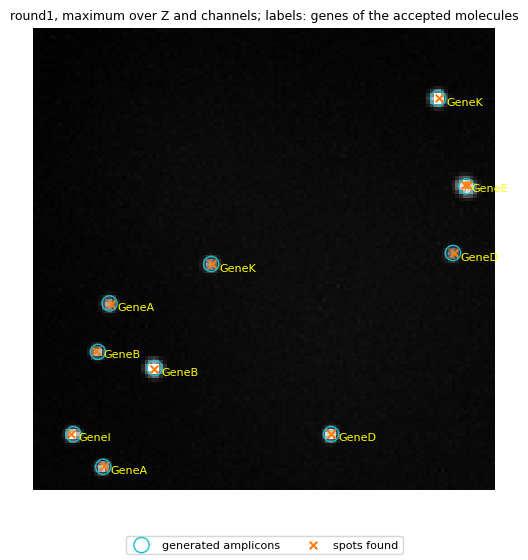

In [6]:
projection = fov.images["round1"].max(axis=(0, 3))
accepted = spots.merge(reads.loc[reads.accepted, ["spot_id", "gene_id"]], on="spot_id")
generated_yx = np.array([spot["position"][1:] for spot in truth["spots"]])
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(projection, cmap="gray", vmax=np.percentile(projection, 99.9))
ax.scatter(generated_yx[:, 1], generated_yx[:, 0], s=120, facecolors="none", edgecolors="tab:cyan",
           label="generated amplicons")
ax.scatter(spots.x, spots.y, s=30, marker="x", c="tab:orange", label="spots found")
labelled = []
for row in accepted.itertuples():
    # One label for spots of one gene within two pixels of each other.
    if not any(gene == row.gene_id and abs(y - row.y) <= 2 and abs(x - row.x) <= 2 for gene, y, x in labelled):
        ax.annotate(row.gene_id, (row.x, row.y), xytext=(5, -5), textcoords="offset points", color="yellow", fontsize=8)
        labelled.append((row.gene_id, row.y, row.x))
ax.set_title("round1, maximum over Z and channels; labels: genes of the accepted molecules", fontsize=9)
fig.legend(loc="lower center", ncol=2, fontsize=8)
ax.set_axis_off()
plt.show()

The second figure is a small read QC: the reads per gene beside the generated amplicons
per gene, and each read's decoder distance (smaller is closer to its codebook entry).

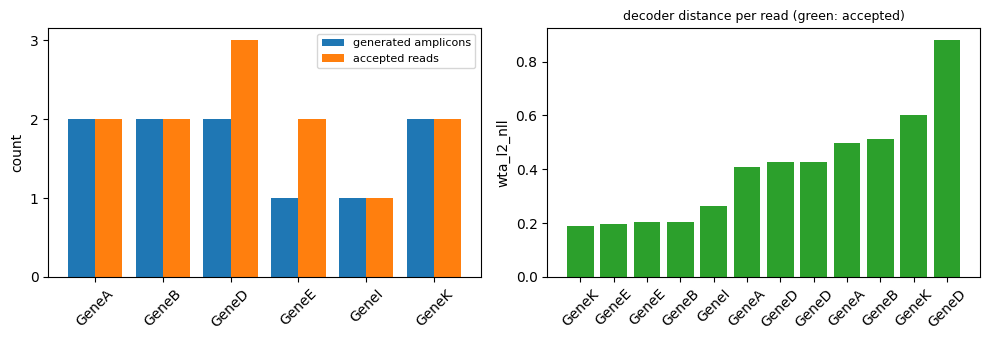

In [7]:
genes = sorted(set(reads.gene_id.dropna()) | {spot["gene"] for spot in truth["spots"]})
read_counts = reads[reads.accepted].gene_id.value_counts().reindex(genes, fill_value=0)
generated_counts = pd.Series([spot["gene"] for spot in truth["spots"]]).value_counts().reindex(genes, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
position = np.arange(len(genes))
axes[0].bar(position - 0.2, generated_counts, width=0.4, label="generated amplicons")
axes[0].bar(position + 0.2, read_counts, width=0.4, label="accepted reads")
axes[0].set_xticks(position, genes, rotation=45)
axes[0].set_ylabel("count")
axes[0].yaxis.get_major_locator().set_params(integer=True)
axes[0].legend(fontsize=8)
ordered = reads.sort_values("wta_l2_nll")
axes[1].bar(np.arange(len(ordered)), ordered.wta_l2_nll,
            color=["tab:green" if a else "tab:red" for a in ordered.accepted])
axes[1].set_xticks(np.arange(len(ordered)), ordered.gene_id, rotation=45)
axes[1].set_ylabel("wta_l2_nll")
axes[1].set_title("decoder distance per read (green: accepted)", fontsize=9)
fig.tight_layout()
plt.show()

## 5. The molecule table

`export_spots()` writes `molecules.csv`, the accepted molecules: their spot identity,
zero-based position in the reference grid, gene and codebook entry (`qc_score` is empty
because this pipeline has no read-scoring step). It is the input of
cell assignment and of the sample export
([Checkpoints and run records](../../docs/checkpoints.md)).

In [8]:
molecules_path = fov.export_spots()
molecules = pd.read_csv(molecules_path)
print("written:", molecules_path.relative_to(OUTPUT).as_posix(), f"({len(molecules)} rows)")
print(molecules.drop(columns="spot_namespace").to_string(index=False))

written: fovs/FOV_001/molecules.csv (12 rows)
 spot_id  z   y   x gene_id entry_id  qc_score
       0  6  43 119   GeneE    CTGAC       NaN
       1  2 112  10   GeneI    CAAAC       NaN
       2  2 112  82   GeneD    CGTAC       NaN
       3  3  62 116   GeneD    CGTAC       NaN
       4  2 112  82   GeneD    CGTAC       NaN
       5  6  43 120   GeneE    CTGAC       NaN
       6  2  19 112   GeneK    CCCGC       NaN
       7  1  94  33   GeneB    CATGC       NaN
       8  1 121  19   GeneA    CACGC       NaN
       9  3  89  17   GeneB    CATGC       NaN
      10  2  76  21   GeneA    CACGC       NaN
      11  2  65  49   GeneK    CCCGC       NaN


## 6. A short look at `run.json`

`fovs/<FOV>/run.json` is the run record: the identity of the run, its inputs, the
configuration, each step with its status, the transforms, the counts and the outputs.
The processing report of a sample reads these records
([Checkpoints and run records](../../docs/checkpoints.md), "run.json").

In [9]:
record = json.loads(fov.paths.run_record.read_text())
print("keys:", list(record))
print("status:", record["status"], " reference round:", record["rounds"]["reference_round"])
print("steps:", [(step["name"], step["round"], step["status"]) for step in record["steps"]][:6], "…")
print("counts.filtering:", record["counts"]["filtering"])
print("genes:", record["counts"]["summary"]["genes"])
print("outputs:", {name: {k: v for k, v in entry.items() if k in ("path", "rows")}
                   for name, entry in record["outputs"].items()})

keys: ['format_version', 'dataset_id', 'sample_id', 'fov_id', 'subtile_id', 'input_root', 'output_root', 'status', 'started_at', 'ended_at', 'error', 'code', 'environment', 'config', 'workflow_config', 'channels', 'rounds', 'inputs', 'codebook', 'steps', 'preprocessing', 'registration', 'transforms', 'counts', 'checkpoint_directory', 'checkpoints', 'outputs']
status: succeeded  reference round: round1
steps: [('load_images', None, 'succeeded'), ('find_spots', None, 'succeeded'), ('extract_round', 'round1', 'succeeded'), ('register', 'round2', 'succeeded'), ('extract_round', 'round2', 'succeeded'), ('register', 'round3', 'succeeded')] …
counts.filtering: {'total': 12, 'accepted': 12, 'rejected': 0, 'fractions': {'accepted': 1.0}}
genes: {'GeneA': 2, 'GeneB': 2, 'GeneD': 3, 'GeneE': 2, 'GeneI': 1, 'GeneK': 2}
outputs: {'reads': {'path': 'reads.csv', 'rows': 12}, 'molecules': {'path': 'molecules.csv', 'rows': 12}}


## Clean up

The notebook wrote only inside its temporary workspace; removing it leaves nothing behind.

In [10]:
written = sorted(p.relative_to(WORKSPACE).as_posix() for p in WORKSPACE.rglob("*") if p.is_file())
print(len(written), "files written, under", sorted({path.split("/")[0] for path in written}))
workspace.cleanup()
print("workspace removed:", not WORKSPACE.exists())

25 files written, under ['input', 'results']
workspace removed: True
